# 02a · Deeper exploration of the training data

A supplement to notebooks 01 and 02: composition effects, weather persistence, reporting conventions and feature representation. **January–September 2025 only**; later-period outcomes are not explored. This notebook reads existing handoffs and raw weather, writes no datasets, does not change A/B or sample membership, and fits no classifier.

These are exploratory associations, not causal effects or estimates of future model performance. Multiple flights share weather reports and airport-days. Flight counts do not represent independent weather experiments. Shared-mix comparisons require at least 30 flights in each exposure group; sensitivity checks use 10 and 50. The representation corrections are applied in 01/02 and audited below; additional feature candidates remain for review; notebook 03 remains the planned modelling stage.


In [1]:
from pathlib import Path
import site
if site.ENABLE_USER_SITE:
    site.addsitedir(site.getusersitepackages())
import hashlib
import json
import re

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from matplotlib.ticker import PercentFormatter
import seaborn as sns
from sklearn.impute import SimpleImputer
from sklearn.pipeline import make_pipeline
from sklearn.preprocessing import OneHotEncoder, StandardScaler

ROOT = Path.cwd().resolve()
if ROOT.name == 'notebooks':
    ROOT = ROOT.parent
if (ROOT / 'departure-delay-classification/config/project.json').is_file():
    ROOT = ROOT / 'departure-delay-classification'
CONFIG = json.loads((ROOT / 'config/project.json').read_text())
MANIFEST = json.loads((ROOT / 'reports/preparation_manifest.json').read_text())
INPUTS = ['notebooks/01_cleaning_and_eda.ipynb', 'notebooks/02_feature_engineering.ipynb',
          'data/processed/flights_clean.parquet', 'data/processed/features.parquet',
          'config/project.json', 'reports/preparation_manifest.json']

def sha256(path):
    with path.open('rb') as stream:
        return hashlib.file_digest(stream, 'sha256').hexdigest()

input_hashes = {name: sha256(ROOT / name) for name in INPUTS}
for kind in ['input', 'output']:
    provenance = MANIFEST['feature_engineering']
    assert input_hashes[provenance[kind]] == provenance[kind + '_sha256'], 'Rebuild a stale handoff first.'
train = pd.read_parquet(ROOT / 'data/processed/features.parquet', filters=[('split', '==', 'train')])
scheduled = pd.read_parquet(ROOT / 'data/processed/flights_clean.parquet', filters=[('split', '==', 'train')])
train = train.merge(scheduled[['flight_id', 'departure_hour', 'departure_delay_minutes']],
                    on='flight_id', validate='one_to_one')
assert train['flight_id'].is_unique and train['split'].eq('train').all()
assert train['flight_date'].between(CONFIG['split']['train_start'], CONFIG['split']['train_end']).all()
TARGET = 'delayed_departure'
BANDS = ['00–05 overnight', '06–11 morning', '12–17 afternoon', '18–23 evening']
GROUPS = ['origin', 'month', 'departure_time_band']
sns.set_theme(style='whitegrid', palette=['#247BA0', '#E08D3C', '#5C946E'])
plt.rcParams.update({'figure.dpi': 110, 'axes.spines.top': False, 'axes.spines.right': False})

def show_table(data, **kwargs):
    print(data.to_string(**kwargs))

def show_plot():
    plt.tight_layout()
    plt.show()

def rates(frame, groups):
    return frame.groupby(groups, observed=True)[TARGET].agg(n='size', delay_rate='mean')

print(f'{len(train):,} eligible training flights; {len(scheduled):,} scheduled flights.')
print(f'Overall 15+ minute delay rate: {train[TARGET].mean():.2%}')


698,670 eligible training flights; 712,534 scheduled flights.
Overall 15+ minute delay rate: 25.84%


## 1. Check the corrected month representation

The former one-hot month recipe would make unseen October–December categories all zero when fitted on January–September. The core notebooks now use fixed 12-month sine/cosine coordinates. Compare the former representation with the corrected coordinates using hypothetical calendar values only; no later-period outcomes are loaded. [Encoder behaviour](https://scikit-learn.org/stable/modules/generated/sklearn.preprocessing.OneHotEncoder.html).

Also inspect rare destinations absent from the shared initial-training sample.


       month_1  month_2  month_3  month_4  month_5  month_6  month_7  month_8  month_9
month                                                                                 
10         0.0      0.0      0.0      0.0      0.0      0.0      0.0      0.0      0.0
11         0.0      0.0      0.0      0.0      0.0      0.0      0.0      0.0      0.0
12         0.0      0.0      0.0      0.0      0.0      0.0      0.0      0.0      0.0
   month  month_sin     month_cos
0     10  -1.000000 -1.836970e-16
1     11  -0.866025  5.000000e-01
2     12  -0.500000  8.660254e-01


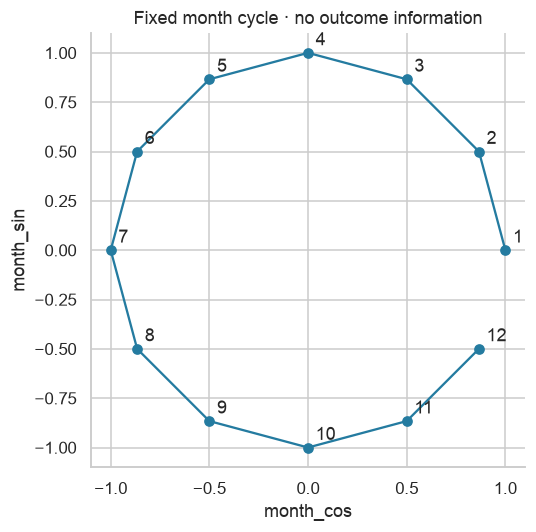

              n  delay_rate
destination                
ACK          27    0.111111
GTF          13    0.000000
HYA          11    0.272727
KOA          16    0.187500
4 destinations absent from the sample; 67 training-population flights affected.


In [2]:
sample = train.loc[train['model_sample']].copy()
month_encoder = OneHotEncoder(handle_unknown='ignore', sparse_output=False)
month_encoder.fit(sample[['month']])
hypothetical = pd.DataFrame({'month': [10, 11, 12]}, dtype='int8')
show_table(pd.DataFrame(month_encoder.transform(hypothetical),
                       columns=month_encoder.get_feature_names_out(), index=hypothetical['month']))
angles = 2 * np.pi * (hypothetical['month'] - 1) / 12
show_table(hypothetical.assign(month_sin=np.sin(angles), month_cos=np.cos(angles)))
assert np.allclose(train['month_sin'], np.sin(2 * np.pi * (train['month'] - 1) / 12))
assert np.allclose(train['month_cos'], np.cos(2 * np.pi * (train['month'] - 1) / 12))
months = np.arange(1, 13)
angles = 2 * np.pi * (months - 1) / 12
fig, ax = plt.subplots(figsize=(6, 5))
ax.plot(np.cos(angles), np.sin(angles), marker='o')
for month, x, y in zip(months, np.cos(angles), np.sin(angles)):
    ax.annotate(str(month), (x, y), xytext=(5, 5), textcoords='offset points')
ax.set(aspect='equal', title='Fixed month cycle · no outcome information',
       xlabel='month_cos', ylabel='month_sin')
show_plot()
absent = sorted(set(train['destination']) - set(sample['destination']))
rare = train.loc[train['destination'].isin(absent)]
show_table(rates(rare, 'destination'))
print(f'{len(absent)} destinations absent from the sample; {len(rare):,} training-population flights affected.')


**Observed:** four destinations covering 67 training-population flights are absent from the 20,000-flight initial sample. The saved month coordinates match the fixed cycle.

**Meaning:** the saved cyclic coordinates fix the unseen-category representation. They do not supply evidence for unobserved seasons. More years could help establish repeatable seasonality, but are not required for the current A/B comparison. Rare destinations remain in the data; category handling is fitted on the relevant training cohort.


## 2. Verify that repeated missingness indicators were removed

First reproduce the former numerical recipe to show the five identical condition-absence coordinates. Then audit the corrected selective-indicator recipe used by notebook 02: explicit condition/cloud flags remain, and wind/gust can still receive useful automatic missingness indicators. Standardization alone would not remove duplication.


In [3]:
predictors = MANIFEST['feature_engineering']['feature_sets']['B']
categorical = ['airline', 'origin', 'destination', 'weekday']
numeric = [name for name in predictors if name not in categorical]
recipe = make_pipeline(SimpleImputer(strategy='median', add_indicator=True, keep_empty_features=True),
                       StandardScaler())
transformed = recipe.fit_transform(sample[numeric])
names = list(recipe[0].get_feature_names_out(numeric))
condition_flags = ['rain_reported', 'frozen_precip_reported', 'fog_or_mist_reported', 'thunder_reported']
repeated = ['condition_codes_missing'] + ['missingindicator_' + name for name in condition_flags]
values = transformed[:, [names.index(name) for name in repeated]]
assert np.allclose(values, values[:, [0]])
show_table(pd.Series(repeated, name='former_five_identical_columns').to_frame(), index=False)
covered = CONFIG['preprocessing']['explicit_missingness_covered_columns']
corrected_names, corrected_blocks = [], []
for columns, add_indicators in [([c for c in numeric if c not in covered], True),
                                ([c for c in numeric if c in covered], False)]:
    imputer = SimpleImputer(strategy='median', add_indicator=add_indicators, keep_empty_features=True)
    corrected_blocks.append(StandardScaler().fit_transform(imputer.fit_transform(sample[columns])))
    corrected_names.extend(imputer.get_feature_names_out(columns))
assert not any('missingindicator_' + name in corrected_names for name in covered)
for name in ['wind_knots', 'gust_knots']:
    if sample[name].isna().any():
        assert 'missingindicator_' + name in corrected_names
assert np.isfinite(np.column_stack(corrected_blocks)).all()
show_table(pd.DataFrame({'recipe': ['former', 'corrected'],
                        'numeric_columns': [len(names), len(corrected_names)],
                        'condition_absence_coordinates': [5, 1]}))
print('Corrected automatic indicators:', [c for c in corrected_names if c.startswith('missingindicator_')])
show_table(train[predictors].nunique().loc[lambda s: s <= 1].rename('distinct_training_values').to_frame())
print('Ceiling missingness equals the no-ceiling flag in training:',
      train['ceiling_ft'].isna().eq(train['no_ceiling_reported'].eq(1)).all())
print('Distance/duration correlation:', train['distance_miles'].corr(train['scheduled_duration_minutes']))
show_table(train[['gust_knots', 'rain_reported', 'fog_or_mist_reported']].median().to_frame('nonmissing_median'))


          former_five_identical_columns
                condition_codes_missing
         missingindicator_rain_reported
missingindicator_frozen_precip_reported
  missingindicator_fog_or_mist_reported
      missingindicator_thunder_reported
      recipe  numeric_columns  condition_absence_coordinates
0     former               40                              5
1  corrected               35                              1
Corrected automatic indicators: ['missingindicator_wind_knots', 'missingindicator_gust_knots']
                           distinct_training_values
cloud_coverage_missing                            1
ceiling_height_missing                            1
weather_report_missing                            1
history_origin_no_history                         1
Ceiling missingness equals the no-ceiling flag in training: True
Distance/duration correlation: 0.9859303881450463
                      nonmissing_median
gust_knots                         22.0
rain_reported              

**Observed:** the former recipe produces five identical condition-absence coordinates. The corrected recipe retains one, reducing numeric output from 40 to 35 columns while preserving wind/gust missingness indicators.

**Meaning:** the former five identical coordinates gave condition absence five times its single-coordinate contribution to squared Euclidean distance. The corrected recipe retains the explicit absence flag without the repeated automatic copies. This fixes representation; classifier performance still needs validation.

Distance/duration remain correlated candidates for later comparison. A median-filled condition value is a computational placeholder; interpret it with the missingness flag.


## 3. Full weather text reveals information omitted by four cloud columns

Read source files referenced by training flights, including a three-hour warm-up. Keep the approved exclusions and stop on any other duplicate observation key. Parse cloud groups only in the METAR body before RMK; remarks do not become current cloud layers.


In [4]:
columns = ['station', 'valid', 'metar', 'wxcodes', 'dwpf', 'p01i'] + [f'skyc{i}' for i in range(1, 5)] + [f'skyl{i}' for i in range(1, 5)]
parts = []
for source in sorted(train['weather_source_file'].dropna().unique()):
    raw = pd.read_csv(ROOT / source, usecols=columns, dtype='string', keep_default_na=False)
    raw = raw.loc[raw['station'].isin(CONFIG['scope']['origin_airports'])].copy()
    for column in columns:
        raw[column] = raw[column].str.strip()
    parts.append(raw)
weather = pd.concat(parts, ignore_index=True).drop_duplicates(columns).rename(columns={'station': 'origin'})
weather['weather_observed_utc'] = pd.to_datetime(weather['valid'], utc=True).astype('datetime64[ns, UTC]')
approved = pd.MultiIndex.from_tuples([tuple(key) for key in CONFIG['weather_quality']['excluded_station_times']])
weather = weather.loc[~pd.MultiIndex.from_frame(weather[['origin', 'valid']]).isin(approved)].copy()
weather = weather.loc[weather['weather_observed_utc'].between(
    train['weather_observed_utc'].min() - pd.Timedelta(hours=3), train['weather_observed_utc'].max())].copy()
assert not weather.duplicated(['origin', 'weather_observed_utc']).any()
weather = weather.sort_values(['origin', 'weather_observed_utc']).reset_index(drop=True)
body = weather['metar'].str.split(r'\s+RMK(?:\s|$)', n=1, regex=True).str[0]
weather['cloud_groups'] = body.str.findall(r'(?<!\S)(?:FEW|SCT|BKN|OVC|VV)(?:\d{3}|///)(?:CB|TCU)?(?=\s|=|$)')

def body_ceiling(groups):
    if any(g.startswith(('BKN', 'OVC', 'VV')) and '///' in g for g in groups):
        return np.nan
    heights = [int(re.search(r'\d{3}', group).group()) * 100 for group in groups
               if group.startswith(('BKN', 'OVC', 'VV')) and '///' not in group]
    return min(heights) if heights else np.nan

weather['body_ceiling_ft'] = weather['cloud_groups'].map(body_ceiling)
coverage = weather[[f'skyc{i}' for i in range(1, 5)]]
heights = weather[[f'skyl{i}' for i in range(1, 5)]].apply(pd.to_numeric, errors='coerce')
heights.columns = coverage.columns
ceiling_layers = coverage.isin(['BKN', 'OVC', 'VV'])
weather['four_column_ceiling_ft'] = heights.where(ceiling_layers).min(axis=1).mask(
    (ceiling_layers & heights.isna()).any(axis=1))
weather['explicit_status_flag'] = weather['metar'].str.contains(r'\b(?:PWINO|TSNO|FZRANO|FZNO|PNO)\b', regex=True)
audit = train.merge(weather[['origin', 'weather_observed_utc', 'metar', 'wxcodes', 'dwpf',
                            'body_ceiling_ft', 'four_column_ceiling_ft', 'explicit_status_flag']],
                    on=['origin', 'weather_observed_utc'], how='left', validate='many_to_one', indicator=True)
assert audit['_merge'].eq('both').all()
missed_ceiling = audit['ceiling_ft'].isna() & audit['body_ceiling_ft'].notna()
formerly_missed = audit['four_column_ceiling_ft'].isna() & audit['body_ceiling_ft'].notna()
examples = audit.loc[formerly_missed, ['origin', 'weather_observed_utc', 'ceiling_ft',
                                    'body_ceiling_ft', 'no_ceiling_reported', 'metar']].drop_duplicates()
print('Flights where the four-slot source would miss a body ceiling:', int(formerly_missed.sum()))
assert not missed_ceiling.any(), 'Review any remaining known body ceiling omitted from the saved features.'
print(f'{missed_ceiling.sum():,} flights ({missed_ceiling.mean():.3%}) still have an omitted known body ceiling.')
print('Distinct recovered reports:', len(examples))
show_table(examples.head(4), index=False)
print('Recovered ceiling examples (ft):', sorted(examples['body_ceiling_ft'].unique()))
unknown_conditions = audit['condition_codes_missing'].eq(1)
print(f'No usable condition code: {unknown_conditions.sum():,} flights; '
      f'{(unknown_conditions & audit["explicit_status_flag"]).sum():,} also have explicit status tokens.')


Flights where the four-slot source would miss a body ceiling: 719
0 flights (0.000%) still have an omitted known body ceiling.
Distinct recovered reports: 17
origin      weather_observed_utc  ceiling_ft  body_ceiling_ft  no_ceiling_reported                                                                                                                                                                          metar
   ATL 2025-04-22 11:52:00+00:00     25000.0          25000.0                  0.0                                                          KATL 221152Z 31006KT 10SM FEW055 FEW080 SCT110 SCT200 OVC250 19/16 A3012 RMK AO2 SLP192 T01940161 10211 20189 53015 $
   DFW 2025-06-13 17:53:00+00:00     25000.0          25000.0                  0.0                                                          KDFW 131753Z 17006KT 10SM FEW045 FEW100 SCT140 SCT180 BKN250 29/21 A2993 RMK AO2 SLP125 T02890206 10294 20217 50000 $
   DFW 2025-06-25 22:53:00+00:00     25000.0          25000.0       

**Observed:** full-body extraction recovers ceilings for 719 initial-training flights that the four-column source would omit. Zero known body ceilings remain omitted in the saved features.

**Meaning:** the saved features now include the known ceilings that the four-slot source alone omitted; the assertion checks for remaining omissions. No flights or labels are changed.

An absent condition-code field does not establish station failure: event-driven groups may be omitted while temperature, wind and visibility remain measured. [NOAA reporting conventions](https://www.weather.gov/media/asos/aum-toc.pdf#page=49) and [IEM missing codes](https://mesonet.agron.iastate.edu/request/download.phtml) explain why absence alone cannot establish sensor health. The current project conservatively retains explicit unknown flags.


## 4. Airline rankings change with the airport and schedule mix

Compare F9 and AA using a common airport × month × time-band mix. Within each shared group, calculate each airline's risk and apply identical weights based on their combined flight counts. This is descriptive standardization, not a causal estimate of airline quality; route and other differences remain.


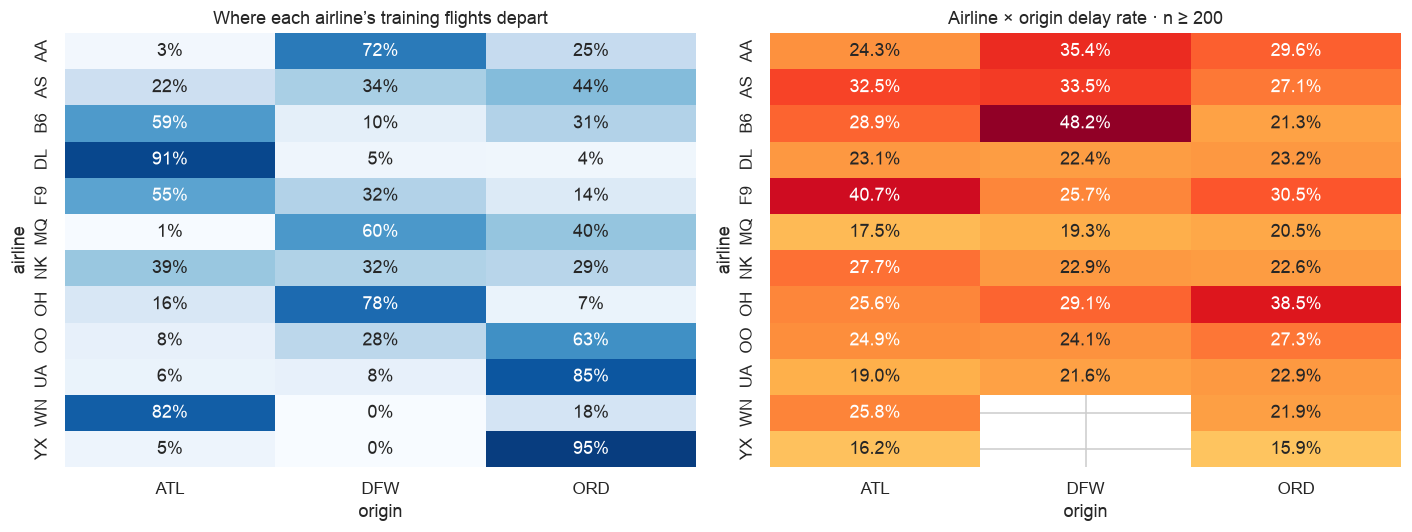

              n  delay_rate
airline                    
AA       165387    0.336405
F9        19315    0.345793
                   F9_vs_AA_shared_mix
shared_groups                95.000000
retained_rows            183589.000000
retained_fraction             0.993974
raw_common_0                  0.337873
raw_common_1                  0.347207
standardized_0                0.333681
standardized_1                0.294364
difference_pp                -3.931688
   min_per_group  shared_groups  retained_rows  retained_fraction  raw_common_0  raw_common_1  standardized_0  standardized_1  difference_pp
0             10            103         184315           0.997905      0.337005      0.346036        0.332678        0.293962      -3.871665
1             30             95         183589           0.993974      0.337873      0.347207        0.333681        0.294364      -3.931688
2             50             76         173049           0.936909      0.335725      0.350562        0.331970     

In [5]:
def shared_mix(frame, exposure, groups=GROUPS, min_n=30):
    grouped = frame.groupby(groups + [exposure], observed=True)[TARGET].agg(n='size', risk='mean')
    counts = grouped['n'].unstack(exposure).reindex(columns=[0, 1])
    risks = grouped['risk'].unstack(exposure).reindex(columns=[0, 1])
    keep = counts.ge(min_n).all(axis=1)
    counts, risks = counts.loc[keep], risks.loc[keep]
    assert len(counts) > 0
    weights = counts.sum(axis=1) / counts.sum().sum()
    means = risks.mul(weights, axis=0).sum()
    common = frame.loc[pd.MultiIndex.from_frame(frame[groups]).isin(counts.index)]
    raw = common.groupby(exposure, observed=True)[TARGET].mean()
    return {'shared_groups': len(counts), 'retained_rows': len(common),
            'retained_fraction': len(common) / len(frame),
            'raw_common_0': raw[0], 'raw_common_1': raw[1],
            'standardized_0': means[0], 'standardized_1': means[1],
            'difference_pp': (means[1] - means[0]) * 100}

mix = pd.crosstab(train['airline'], train['origin'], normalize='index')
airline_origin = rates(train, ['airline', 'origin'])
fig, axes = plt.subplots(1, 2, figsize=(13, 5))
sns.heatmap(mix, annot=True, fmt='.0%', cmap='Blues', vmin=0, vmax=1, ax=axes[0], cbar=False)
axes[0].set_title('Where each airline’s training flights depart')
risk_map = airline_origin['delay_rate'].unstack().where(airline_origin['n'].unstack().ge(200))
sns.heatmap(risk_map, annot=True, fmt='.1%', cmap='YlOrRd',
            vmin=0, vmax=.5, ax=axes[1], cbar=False)
axes[1].set_title('Airline × origin delay rate · n ≥ 200')
show_plot()
pair = train.loc[train['airline'].isin(['F9', 'AA'])].copy()
pair['is_F9'] = pair['airline'].eq('F9').astype(int)
airline_comparison = shared_mix(pair, 'is_F9')
show_table(rates(pair, 'airline'))
show_table(pd.Series(airline_comparison).to_frame('F9_vs_AA_shared_mix'))
show_table(pd.DataFrame([dict(min_per_group=n, **shared_mix(pair, 'is_F9', min_n=n))
                         for n in [10, 30, 50]]))


**Observed:** F9 has a crude delay rate of 34.58% versus AA at 33.64%. On the shared airport/month/time-band mix, their rates are 29.44% and 33.37%. The comparison retains 99.4% of their combined flights; the reversal persists at minimum counts of 10 and 50.

**Interpretation:** compare the crude, common-population and shared-mix results above, including sensitivity to the minimum count. A reversal or reduction means airline comparisons depend on the airport and schedule mix. This does not establish that one airline would operate another airline's flights better.


## 5. Weather associations depend on departure time

Precipitation is an accumulation report, not guaranteed rain at departure. Inspect interactions and banded visibility/wind relationships rather than relying on one correlation.


precip_state         positive_minus_zero_pp  positive_to_zero_ratio
departure_time_band                                                
00–05 overnight                    8.274383                1.844942
06–11 morning                     13.259883                1.855935
12–17 afternoon                   22.892628                1.871010
18–23 evening                     27.905515                1.833105


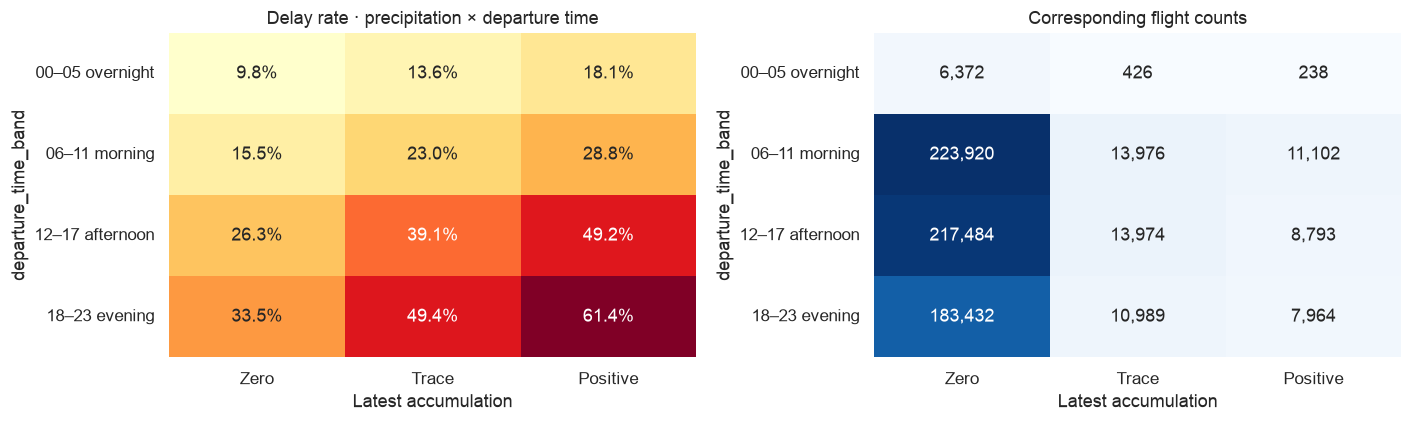

                   positive_vs_nonpositive
shared_groups                    76.000000
retained_rows                648012.000000
retained_fraction                 0.927494
raw_common_0                      0.250678
raw_common_1                      0.445159
standardized_0                    0.250662
standardized_1                    0.471473
difference_pp                    22.081084


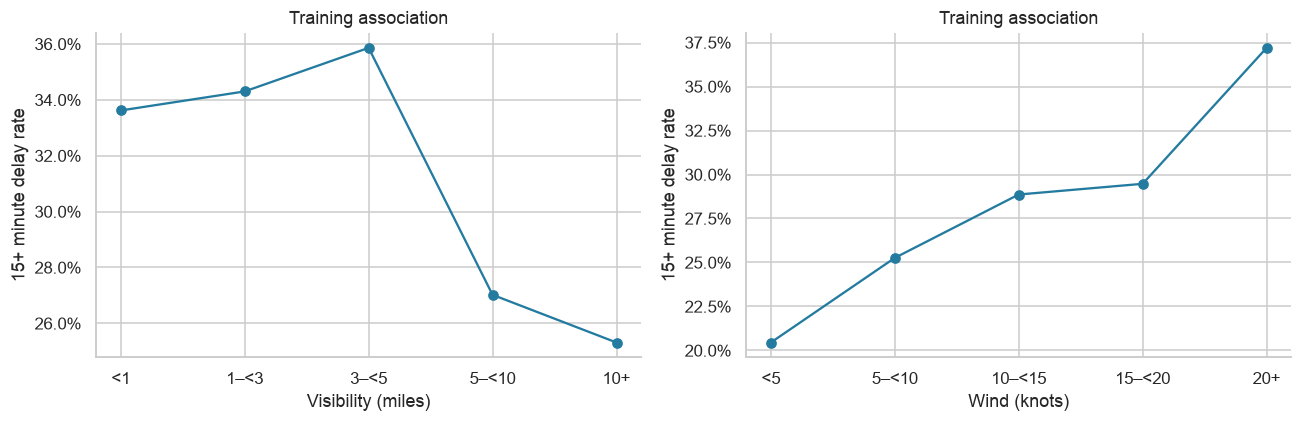

Visibility stored at exactly 10 miles: 87.7%


In [6]:
train['precip_state'] = np.select([train['precip_trace'].eq(1), train['precip_inches'].gt(0)],
                                 ['Trace', 'Positive'], default='Zero')
interaction = rates(train, ['departure_time_band', 'precip_state'])
contrast = interaction['delay_rate'].unstack().reindex(BANDS)
contrast['positive_minus_zero_pp'] = (contrast['Positive'] - contrast['Zero']) * 100
contrast['positive_to_zero_ratio'] = contrast['Positive'] / contrast['Zero']
show_table(contrast[['positive_minus_zero_pp', 'positive_to_zero_ratio']])
fig, axes = plt.subplots(1, 2, figsize=(13, 4))
sns.heatmap(interaction['delay_rate'].unstack().reindex(BANDS)[['Zero', 'Trace', 'Positive']],
            annot=True, fmt='.1%', cmap='YlOrRd', ax=axes[0], cbar=False)
axes[0].set(title='Delay rate · precipitation × departure time', xlabel='Latest accumulation')
sns.heatmap(interaction['n'].unstack().reindex(BANDS)[['Zero', 'Trace', 'Positive']],
            annot=True, fmt=',.0f', cmap='Blues', ax=axes[1], cbar=False)
axes[1].set(title='Corresponding flight counts', xlabel='Latest accumulation')
show_plot()
train['positive_accumulation'] = train['precip_inches'].gt(0).astype(int)
show_table(pd.Series(shared_mix(train, 'positive_accumulation')).to_frame('positive_vs_nonpositive'))
train['visibility_band'] = pd.cut(train['visibility_miles'], [-np.inf, 1, 3, 5, 10, np.inf],
                                 right=False, labels=['<1', '1–<3', '3–<5', '5–<10', '10+'])
train['wind_band'] = pd.cut(train['wind_knots'], [-np.inf, 5, 10, 15, 20, np.inf],
                           right=False, labels=['<5', '5–<10', '10–<15', '15–<20', '20+'])
fig, axes = plt.subplots(1, 2, figsize=(12, 4))
for column, ax, label in zip(['visibility_band', 'wind_band'], axes, ['Visibility (miles)', 'Wind (knots)']):
    table = rates(train, column)
    ax.plot(table.index.astype(str), table['delay_rate'], marker='o')
    ax.set(xlabel=label, ylabel='15+ minute delay rate', title='Training association')
    ax.yaxis.set_major_formatter(PercentFormatter(1))
show_plot()
print(f'Visibility stored at exactly 10 miles: {train["visibility_miles"].eq(10).mean():.1%}')


**Observed:** the positive-versus-zero accumulation contrast is 13.26 percentage points in the morning and 27.91 points in the evening. Relative risks remain similar (1.86 and 1.83). Visibility is stored at exactly 10 miles for 87.7% of training flights.

**Interpretation:** compare both percentage-point differences and risk ratios. A larger absolute precipitation contrast in the evening does not by itself prove a distinct interaction on every scale or establish that a new term will improve prediction. Keep it as a validation candidate.

Very low visibility need not have the highest observed delay rate: airport, clock, season and cancellation exclusions affect the mix. The table above records values stored at exactly 10 miles; [NOAA documents 10SM for visibility of 10 miles or more](https://www.weather.gov/media/asos/aum-toc.pdf#page=36). This is a reporting ceiling. IQR flags should not trigger deletion.


## 6. Earlier weather can matter when the latest accumulation is zero

For each observation, check whether any earlier report in [observation−3h, observation) had positive measured accumulation. All reports predate the simulated cutoff. Never sum these overlapping accumulation totals. This in-memory diagnostic is not added to B.


                                       n  delay_rate
weather_history_state                               
Latest positive                    28097    0.443072
Latest trace                       39365    0.359761
Latest zero; earlier positive      20074    0.395387
Latest zero; no earlier positive  611134    0.238866


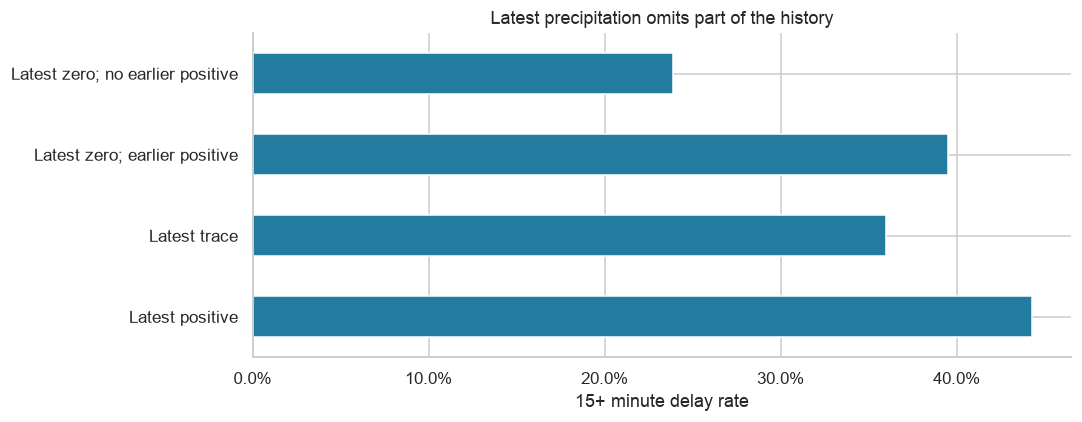

                   earlier_positive_vs_no_earlier_positive
shared_groups                                    79.000000
retained_rows                                608865.000000
retained_fraction                                 0.964603
raw_common_0                                      0.240694
raw_common_1                                      0.397888
standardized_0                                    0.241398
standardized_1                                    0.383102
difference_pp                                    14.170405
                                 n  delay_rate
origin earlier_positive_3h                    
ATL    0                    199110    0.221390
       1                      7451    0.385854
DFW    0                    207702    0.271033
       1                      5172    0.457270
ORD    0                    204322    0.223197
       1                      7451    0.361965
                   within_same_airport_day_and_time_band
shared_groups                       

In [7]:
weather['precip_numeric'] = pd.to_numeric(weather['p01i'].replace({'M': None, 'T': '0', '': None}), errors='coerce')
weather['earlier_positive_3h'] = False
weather['earlier_reports_3h'] = 0
for origin, indices in weather.groupby('origin', observed=True).groups.items():
    block = weather.loc[indices]
    times = block['weather_observed_utc'].array.asi8
    left = np.searchsorted(times, times - pd.Timedelta(hours=3).value, side='left')
    end = np.arange(len(block))
    positives = np.r_[0, block['precip_numeric'].gt(0).to_numpy().cumsum()]
    weather.loc[indices, 'earlier_positive_3h'] = positives[end] - positives[left] > 0
    weather.loc[indices, 'earlier_reports_3h'] = end - left
recent = train.merge(weather[['origin', 'weather_observed_utc', 'earlier_positive_3h', 'earlier_reports_3h']],
                     on=['origin', 'weather_observed_utc'], validate='many_to_one')
recent['weather_history_state'] = np.select(
    [recent['precip_inches'].gt(0), recent['precip_trace'].eq(1),
     recent['precip_inches'].eq(0) & recent['earlier_positive_3h'], recent['earlier_reports_3h'].eq(0)],
    ['Latest positive', 'Latest trace', 'Latest zero; earlier positive', 'No earlier report'],
    default='Latest zero; no earlier positive')
recent_rates = rates(recent, 'weather_history_state')
show_table(recent_rates)
fig, ax = plt.subplots(figsize=(10, 4))
recent_rates['delay_rate'].plot.barh(ax=ax)
ax.xaxis.set_major_formatter(PercentFormatter(1))
ax.set(xlabel='15+ minute delay rate', ylabel='', title='Latest precipitation omits part of the history')
show_plot()
zero = recent.loc[recent['precip_inches'].eq(0) & recent['precip_trace'].eq(0) & recent['earlier_reports_3h'].gt(0)].copy()
zero['earlier_positive_3h'] = zero['earlier_positive_3h'].astype(int)
recent_comparison = shared_mix(zero, 'earlier_positive_3h')
show_table(pd.Series(recent_comparison).to_frame('earlier_positive_vs_no_earlier_positive'))
show_table(rates(zero, ['origin', 'earlier_positive_3h']))

within_day_comparison = shared_mix(zero, 'earlier_positive_3h', ['origin', 'flight_date', 'departure_time_band'])
show_table(pd.Series(within_day_comparison).to_frame('within_same_airport_day_and_time_band'))


**Observed:** latest-zero flights with earlier positive accumulation have about 39.5% delay versus 23.9% without it. Airport/month/time standardization gives a 14.17-point gap. The stricter same-airport/day/time comparison gives only 0.35 points and retains 30,974 flights, or 4.9% of the eligible latest-zero comparison population.

**Interpretation:** compare latest-zero flights with and without earlier positive accumulation. Shared disrupted days, other weather and airline/route differences can explain part of the association. Lingering disruption remains a possible explanation, not an established cause or demonstrated predictive gain. [IEM cautions against summing repeated accumulation reports](https://mesonet.agron.iastate.edu/onsite/news.phtml?id=1434).

The stricter same-airport/day/time comparison changes the overlap population and can retain a small share of flights. Read its effect size together with retained_fraction and shared_groups; it cannot settle the effect for all days. No extra weather-history feature is added to B here.


## 7. Traffic behaves differently across airports

The original heatmap compared predictors with other predictors, not with the target. Its small entries do not establish traffic is useless. Compare high (≥60) versus low (≤40) prior-hour departures within shared origin × month × scheduled-hour groups. Middle values are omitted only from this diagnostic, not from project data.


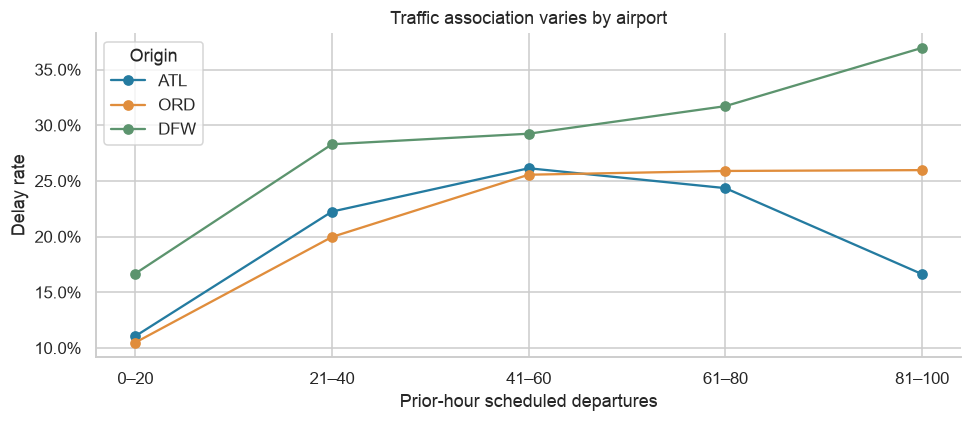

                          n  delay_rate
origin traffic_band                    
ATL    0–20           10907    0.110571
       21–40          44665    0.222456
       41–60         125913    0.261363
       61–80          49631    0.243517
       81–100           878    0.166287
DFW    0–20           14223    0.166772
       21–40          61896    0.282926
       41–60          88194    0.292390
       61–80          56847    0.317150
       81–100          9356    0.369496
ORD    0–20           10719    0.104861
       21–40          34957    0.199674
       41–60         102535    0.255562
       61–80          79843    0.258933
       81–100          8106    0.259684


                   n  delay_rate
high_traffic                    
0             177367    0.220616
1             220806    0.275178
                   high_vs_low_traffic_shared_mix
shared_groups                          223.000000
retained_rows                       184278.000000
retained_fraction                        0.462809
raw_common_0                             0.240242
raw_common_1                             0.267251
standardized_0                           0.232303
standardized_1                           0.275050
difference_pp                            4.274685


In [8]:
traffic_name = 'airport_scheduled_departures_prior_60m'
train['traffic_band'] = pd.cut(train[traffic_name], [-1, 20, 40, 60, 80, 100],
                              labels=['0–20', '21–40', '41–60', '61–80', '81–100'])
traffic_rates = rates(train, ['origin', 'traffic_band'])
fig, ax = plt.subplots(figsize=(9, 4))
for origin in CONFIG['scope']['origin_airports']:
    line = traffic_rates.loc[origin]
    ax.plot(line.index.astype(str), line['delay_rate'], marker='o', label=origin)
ax.yaxis.set_major_formatter(PercentFormatter(1))
ax.set(xlabel='Prior-hour scheduled departures', ylabel='Delay rate', title='Traffic association varies by airport')
ax.legend(title='Origin')
show_plot()
show_table(traffic_rates)
traffic_compare = train.loc[train[traffic_name].le(40) | train[traffic_name].ge(60)].copy()
traffic_compare['high_traffic'] = traffic_compare[traffic_name].ge(60).astype(int)
show_table(rates(traffic_compare, 'high_traffic'))
show_table(pd.Series(shared_mix(traffic_compare, 'high_traffic', ['origin', 'month', 'departure_hour']))
           .to_frame('high_vs_low_traffic_shared_mix'))


**Observed:** the high-versus-low traffic contrast is about 5.46 percentage points crudely and 4.27 points after shared-mix adjustment. The adjusted comparison retains 184,278 flights in 223 supported groups (46.3% of the high/low comparison population).

**Interpretation:** use both the crude and shared-mix contrast above. They describe supported overlapping situations, rather than every flight or a causal traffic effect. Sparse airport/band counts can reverse an apparent trend. Absolute schedule volume is not a measurement of airport capacity. Relative-to-typical traffic remains a possible future candidate.


## 8. Slow historical averages miss sudden bad days

Aggregate by origin and local flight date. Compare observed operated-departure delay rates with the mean existing lagged origin history. Daily outcomes here are descriptive outputs, never new predictors. Include cancellations to understand the population omitted by the current target.


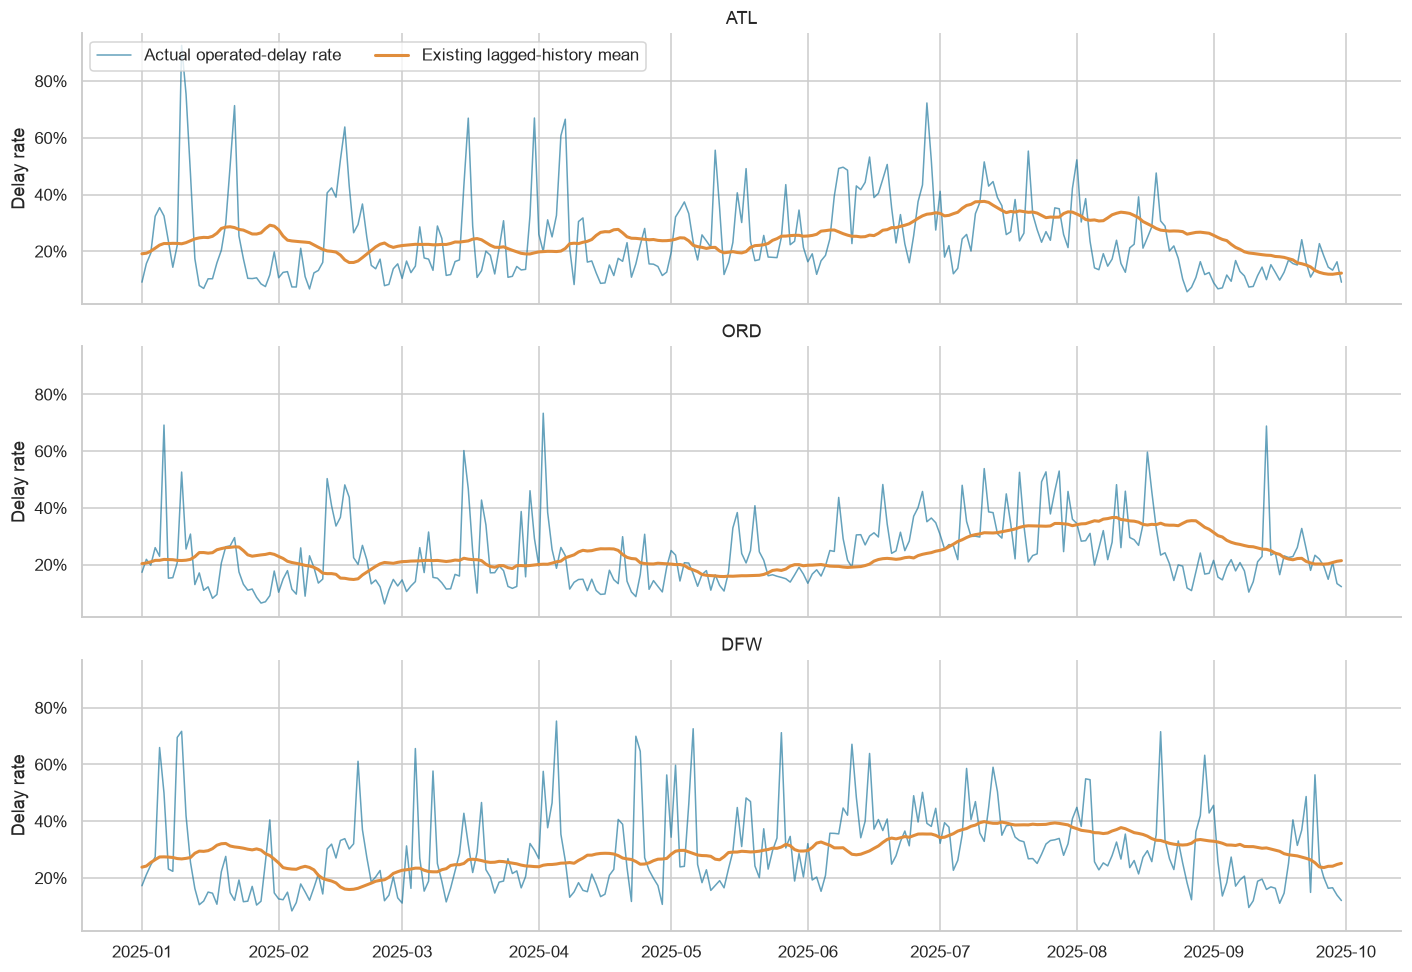

                    operated  delayed  delay_rate  lagged_history  positive_accumulation  scheduled  cancelled  cancel_rate  history_gap  cancelled_or_delayed_rate
origin flight_date                                                                                                                                                 
ATL    2025-01-10        121      112    0.925620        0.226561               0.727273        764      643.0     0.841623     0.699059                   0.988220
ORD    2025-04-02        578      424    0.733564        0.201540               0.653979        821      243.0     0.295981     0.532024                   0.812424
ATL    2025-01-11        541      408    0.754159        0.230642               0.000000        660      119.0     0.180303     0.523517                   0.798485
DFW    2025-04-05        623      469    0.752809        0.249048               0.406100        779      156.0     0.200257     0.503761                   0.802311
ATL    2025-03-3

In [9]:
daily = train.groupby(['origin', 'flight_date'], observed=True).agg(
    operated=(TARGET, 'size'), delayed=(TARGET, 'sum'), delay_rate=(TARGET, 'mean'),
    lagged_history=('history_origin_rate', 'mean'), positive_accumulation=('positive_accumulation', 'mean'))
schedule_days = scheduled.groupby(['origin', 'flight_date'], observed=True).agg(
    scheduled=('flight_id', 'size'), cancelled=('cancelled', 'sum'))
daily = daily.join(schedule_days)
daily['cancel_rate'] = daily['cancelled'] / daily['scheduled']
daily['history_gap'] = daily['delay_rate'] - daily['lagged_history']
daily['cancelled_or_delayed_rate'] = (daily['cancelled'] + daily['delayed']) / daily['scheduled']
fig, axes = plt.subplots(3, 1, figsize=(13, 9), sharex=True, sharey=True)
for origin, ax in zip(CONFIG['scope']['origin_airports'], axes):
    line = daily.loc[origin]
    ax.plot(line.index, line['delay_rate'], alpha=.7, linewidth=1, label='Actual operated-delay rate')
    ax.plot(line.index, line['lagged_history'], linewidth=2, label='Existing lagged-history mean')
    ax.yaxis.set_major_formatter(PercentFormatter(1))
    ax.set(title=origin, ylabel='Delay rate')
axes[0].legend(ncol=2, loc='upper left')
show_plot()
show_table(daily.nlargest(6, 'history_gap'))
show_table(daily.nlargest(5, 'cancel_rate'))
print('Correlation across airport-days:', daily['delay_rate'].corr(daily['lagged_history']))
worst = daily.nlargest(int(np.ceil(len(daily) * .1)), 'delay_rate')
print(f'Top 10% airport-days by operated-delay rate: {worst["delayed"].sum()/daily["delayed"].sum():.1%} '
      f'of delays, {worst["operated"].sum()/daily["operated"].sum():.1%} of operated flights.')
print('Cancelled training flights with a recorded departure-delay value:',
      int((scheduled['cancelled'].eq(1) & scheduled['departure_delay_minutes'].notna()).sum()))
assert not scheduled.loc[scheduled['cancelled'].eq(1), 'query_eligible'].any()


**Observed:** on ATL 10 January, 643 of 764 schedules were cancelled; 112 of 121 eligible departures were delayed (92.6%), while lagged history averaged 22.7%. Across training airport-days, actual delay and lagged history correlate about 0.25. The worst 10% of days account for 20.1% of delays and 9.4% of operated flights. There are 647 cancelled training records with a delay value; the cancellation exclusion correctly retains none as queries.

**Interpretation:** the most disrupted days can be far above slow lagged history, and cancellations alter the population of operated flights. The January examples and top-day counts above describe training data only. A latest zero accumulation value does not rule out earlier disruption or other adverse conditions.

The target remains delay among **noncancelled departures with known outcomes**. Cancellations are not on-time flights. Some cancelled records have delay values, so the explicit cancellation flag remains necessary; the assertion checks their exclusion. Daily outcomes here are descriptive, never new predictors.


## 9. Other checks that prevent misleading interpretations

Weather report rows and flights are different units. One report can match many flights, and special reports are more frequent during active weather. Also inspect a physically sensible unused variable without assuming it must improve delay classification.


In [10]:
report_reuse = train.groupby(['origin', 'weather_observed_utc'], observed=True).size()
print(f'{len(train):,} training flights use {len(report_reuse):,} distinct weather reports.')
show_table(report_reuse.quantile([.5, .9, .99, 1]).to_frame('flights_per_matched_report'))
audit['dewpoint_f'] = pd.to_numeric(audit['dwpf'].replace({'M': None, '': None}), errors='coerce')
audit['dewpoint_spread_f'] = audit['temperature_f'] - audit['dewpoint_f']
audit['dewpoint_band'] = pd.cut(audit['dewpoint_spread_f'], [-np.inf, 2, 5, 10, np.inf],
                               right=False, labels=['<2°F', '2–<5°F', '5–<10°F', '10°F+'])
show_table(audit.groupby('dewpoint_band', observed=True).agg(
    n=(TARGET, 'size'), delay_rate=(TARGET, 'mean'),
    visibility_below_3_miles=('visibility_miles', lambda s: s.lt(3).mean())))
show_table(scheduled.loc[scheduled['query_eligible']].nlargest(3, 'departure_delay_minutes')
           [['flight_date', 'airline', 'origin', 'destination', 'departure_delay_minutes']])
print('Departure delay range:', train['departure_delay_minutes'].min(), train['departure_delay_minutes'].max())


698,670 training flights use 18,231 distinct weather reports.
      flights_per_matched_report
0.50                        41.0
0.90                        68.0
0.99                        80.0
1.00                       120.0
                    n  delay_rate  visibility_below_3_miles
dewpoint_band                                              
<2°F             6231    0.247312                  0.526240
2–<5°F          86308    0.268758                  0.131054
5–<10°F        158194    0.226684                  0.004924
10°F+          447937    0.267739                  0.000817
       flight_date airline origin destination  departure_delay_minutes
469574  2025-07-28      AA    ORD         PHL                   2364.0
581177  2025-08-30      AA    ORD         CLT                   2302.0
549405  2025-08-13      AA    ATL         DFW                   2063.0
Departure delay range: -60.0 2364.0


**Observed:** 698,670 training flights share 18,231 weather reports; the median report matches 41 flights and the maximum matches 120. Valid signed delays range from −60 to 2,364 minutes.

**Interpretation:** the reuse counts show why flights are not independent weather experiments. [IEM discusses special reports during active weather](https://mesonet.agron.iastate.edu/onsite/news.phtml?id=1434). Report-level missing fractions may differ from flight-level fractions without a join error.

Small temperature/dew-point spreads can accompany low visibility without a monotonic departure-delay relationship. Dew point exists in the raw data, but its incremental classification benefit is unproven. Extreme valid delays remain for audit; actual delay is never a predictor.


## What these checks justify

1. The core notebooks now use cyclic month coordinates, selective missingness indicators and complete body cloud extraction. The audits above verify these corrections on initial training.
2. Earlier weather, weather × clock interactions and relative traffic remain candidates, not automatic additions to B. Added predictive benefit requires the planned validation comparison.
3. Interpret airline comparisons under comparable mixes, label the conditional target population, and distinguish flights from weather reports and days.
4. Select on October–December 2025 validation, freeze choices, refit on the shared full-2025 sample, then evaluate on Q1 2026. Training exploration does not answer the formal ML objectives.

This supplement reads existing handoffs and changes none of them. Verify their checksums below.


In [11]:
assert {name: sha256(ROOT / name) for name in INPUTS} == input_hashes
print('Read-only exploration verified: all six input files unchanged; no CSV or Parquet outputs created.')


Read-only exploration verified: all six input files unchanged; no CSV or Parquet outputs created.
